In [1]:
import dask.dataframe as dd
from dask.distributed import Client

client = Client(n_workers=2, threads_per_worker=1, memory_limit="2GB")
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 2
Total threads: 2,Total memory: 3.73 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:64622,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:60326,Total threads: 1
Dashboard: http://127.0.0.1:60328/status,Memory: 1.86 GiB
Nanny: tcp://127.0.0.1:55831,


2026-10-10 10:53:01,022 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle b7027f847ffd4946bd05c06d21900a88 initialized by task ('shuffle-transfer-b7027f847ffd4946bd05c06d21900a88', 2) executed on worker tcp://127.0.0.1:60327
2026-10-10 10:53:02,143 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle b7027f847ffd4946bd05c06d21900a88 deactivated due to stimulus 'task-finished-1791647582.1399634'


In [2]:
columnas = {
    "SUCURSAL": "sucursal",
    "ID_POLIZA": "id_poliza",
    "TIPO DE MOVIMIENTO": "movimiento",
    "FECHA DE EMISION": "fecha_emision",
    "FECHA INICIO DE VIGENCIA": "inicio_vigencia",
    "DIAS POR DEVENGAR": "dias_por_devengar",
    "PRIMAS EMITIDAS MONEDA EQUIVALENTE": "prima_emitida",
    "PRIMAS CANCELADAS MONEDA EQUIVALENTE": "prima_cancelada",
    "RPND RETENIDA": "rpnd",
}

ddf = dd.read_csv(
    "datos_anonimizados/reserva_soat_202512_anon.txt",
    sep="~", usecols=list(columnas), dtype=str, blocksize="128MB",
).rename(columns=columnas)

print("Particiones:", ddf.npartitions)
ddf.head()

Particiones: 13


,sucursal,id_poliza,movimiento,fecha_emision,inicio_vigencia,dias_por_devengar,prima_emitida,prima_cancelada,rpnd
0,1,2c9e4025ed178857,EXPEDICION,15/11/2024,08/01/2025,8,201600.0000,0.0000,13365.2033
1,1,d720b7de93e84272,EXPEDICION,28/11/2024,06/01/2025,6,201600.0000,0.0000,10023.9024
2,1,e99bb6dfc48fce3d,EXPEDICION,02/12/2024,01/01/2025,1,424000.0000,0.0000,382.8983
3,1,0865a383a6265849,EXPEDICION,04/12/2024,02/01/2025,2,150100.0000,0.0000,3698.7865
4,1,88e4b8328fea499a,EXPEDICION,05/12/2024,19/01/2025,19,201600.0000,0.0000,31715.5579


In [3]:
for c in ["fecha_emision", "inicio_vigencia"]:
    ddf[c] = dd.to_datetime(ddf[c], format="%d/%m/%Y")
for c in ["dias_por_devengar", "prima_emitida", "prima_cancelada", "rpnd"]:
    ddf[c] = ddf[c].astype(float)

ddf["mes_emision"] = ddf["fecha_emision"].dt.strftime("%Y-%m")
ddf["dias_anticipacion"] = (ddf["inicio_vigencia"] - ddf["fecha_emision"]).dt.days

ddf.to_parquet("datos_anonimizados/reserva_parquet", write_index=False)
print("Listo")

Listo


In [4]:
ddf = dd.read_parquet("datos_anonimizados/reserva_parquet")

print("Filas:", len(ddf))
print()
print(ddf.dtypes)
print()
print("Nulos por columna:")
print(ddf.isna().sum().compute())
print()
print(ddf["movimiento"].value_counts().compute())

Filas: 3316704

sucursal                     string
id_poliza                    string
movimiento                   string
fecha_emision        datetime64[us]
inicio_vigencia      datetime64[us]
dias_por_devengar           float64
prima_emitida               float64
prima_cancelada             float64
rpnd                        float64
mes_emision                  string
dias_anticipacion             int64
dtype: object

Nulos por columna:
sucursal             0
id_poliza            0
movimiento           0
fecha_emision        0
inicio_vigencia      0
dias_por_devengar    0
prima_emitida        0
prima_cancelada      0
rpnd                 0
mes_emision          0
dias_anticipacion    0
dtype: int64

movimiento
EXPEDICION               3315192
CANCELACION DE POLIZA       1512
Name: count, dtype: int64[pyarrow]


In [5]:
import pandas as pd
pd.options.display.float_format = "{:,.0f}".format

print(ddf[["prima_emitida", "rpnd", "dias_anticipacion", "dias_por_devengar"]].describe().compute())

ddf[ddf.movimiento != "EXPEDICION"].head(10)

       prima_emitida      rpnd  dias_anticipacion  dias_por_devengar
count      3,316,704 3,316,704          3,316,704          3,316,704
mean         345,820   183,986                  3                190
std          197,738   149,456                 15                113
min                0  -750,901               -363                  0
25%          213,300    49,375                  1                 87
50%          269,000   167,138                  1                238
75%          518,100   387,323                  1                333
max        1,500,600   785,607                657                846


,sucursal,id_poliza,movimiento,fecha_emision,inicio_vigencia,dias_por_devengar,prima_emitida,prima_cancelada,rpnd,mes_emision,dias_anticipacion
1081,1,5b8edb8d32a685cc,CANCELACION DE POLIZA,2025-01-15,2025-01-30,30,0,"-833,500","-11,493",2025-01,15
1846,1,fb2157c2d522d729,CANCELACION DE POLIZA,2025-01-24,2025-01-27,27,0,"-1,061,500","-18,474",2025-01,3
6937,1,d3b112a56bd3e40a,CANCELACION DE POLIZA,2025-05-12,2025-04-16,106,0,"-839,200","-63,622",2025-05,-26
17243,1,50fdbfc07131b844,CANCELACION DE POLIZA,2025-09-16,2025-09-13,256,0,"-602,400","-282,877",2025-09,-3
20882,1,20cfea3b9cb4837a,CANCELACION DE POLIZA,2025-12-03,2025-11-29,333,0,"-213,300","-374,064",2025-12,-4
20884,1,f3a51c4407800ca6,CANCELACION DE POLIZA,2025-12-03,2025-12-01,335,0,"-387,100","-194,696",2025-12,-2
22856,3,3c22b361ec2ca44b,CANCELACION DE POLIZA,2025-01-15,2024-12-02,0,0,"-1,082,600",0,2025-01,-44
23979,3,a624880e91201614,CANCELACION DE POLIZA,2025-02-04,2025-01-25,25,0,"-618,900","-5,540",2025-02,-10
25146,3,75aad013c45d085d,CANCELACION DE POLIZA,2025-05-09,2025-04-21,51,0,"-701,300","-30,236",2025-05,-18
25292,3,cae2c510b44e4104,CANCELACION DE POLIZA,2025-05-09,2025-04-21,56,0,"-712,800","-33,542",2025-05,-18


In [6]:
por_mes = ddf[ddf.movimiento == "EXPEDICION"].groupby("mes_emision").agg(
    {"id_poliza": "count", "prima_emitida": "sum", "rpnd": "sum"}
).compute().sort_index().rename(columns={"id_poliza": "polizas"})

por_mes.tail(13)

,polizas,prima_emitida,rpnd
mes_emision,,,
2024-12,21262,"9,118,456,376","293,401,071"
2025-01,291042,"101,990,594,801","5,601,598,355"
2025-02,274980,"93,066,093,440","12,792,447,567"
2025-03,274784,"92,956,391,304","20,538,694,140"
2025-04,231121,"78,733,487,432","24,369,112,498"
2025-05,234283,"78,579,929,244","32,800,451,434"
2025-06,225040,"77,931,857,173","38,066,877,511"
2025-07,281311,"95,819,484,641","51,800,703,934"
2025-08,247170,"84,358,075,370","53,098,701,651"


In [7]:
ddf["prima_neta"] = ddf["prima_emitida"] + ddf["prima_cancelada"]

print("Prima emitida:  ", f'{ddf["prima_emitida"].sum().compute():,.0f}')
print("Prima cancelada:", f'{ddf["prima_cancelada"].sum().compute():,.0f}')
print("Prima neta:     ", f'{ddf["prima_neta"].sum().compute():,.0f}')

Prima emitida:   1,146,981,133,297
Prima cancelada: -734,539,661
Prima neta:      1,146,246,593,636


In [8]:
por_mes = ddf[ddf.movimiento == "EXPEDICION"].groupby("mes_emision").agg(
    {"id_poliza": "count", "prima_emitida": "sum", "rpnd": "sum"}
).compute().sort_index().rename(columns={"id_poliza": "polizas"})

por_mes.tail(13)

,polizas,prima_emitida,rpnd
mes_emision,,,
2024-12,21262,"9,118,456,376","293,401,071"
2025-01,291042,"101,990,594,801","5,601,598,355"
2025-02,274980,"93,066,093,440","12,792,447,567"
2025-03,274784,"92,956,391,304","20,538,694,140"
2025-04,231121,"78,733,487,432","24,369,112,498"
2025-05,234283,"78,579,929,244","32,800,451,434"
2025-06,225040,"77,931,857,173","38,066,877,511"
2025-07,281311,"95,819,484,641","51,800,703,934"
2025-08,247170,"84,358,075,370","53,098,701,651"


In [9]:
import matplotlib.pyplot as plt

m = por_mes.loc["2025-01":"2025-12"]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
(m["polizas"] / 1000).plot.bar(ax=ax[0], color="#2a6f97")
ax[0].set_title("Pólizas SOAT emitidas por mes, 2025 (miles)")
ax[0].set_xlabel("")
(m["rpnd"] / 1e9).plot.bar(ax=ax[1], color="#d17a22")
ax[1].set_title("RPND al cierre según mes de emisión (miles de millones COP)")
ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

muestra = ddf[ddf.prima_emitida > 0][["prima_emitida"]].sample(frac=0.02, random_state=1).compute()
plt.figure(figsize=(8, 4))
plt.hist(muestra["prima_emitida"], bins=60, color="#2a6f97")
plt.xscale("log")
plt.title("Distribución de la prima emitida por póliza (escala logarítmica)")
plt.xlabel("Prima emitida (COP)"); plt.ylabel("Pólizas (muestra del 2 %)")
plt.show()

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
import time
import dask.dataframe as dd
from dask.distributed import Client, LocalCluster

def probar(n_workers, memoria):
    cluster = LocalCluster(n_workers=n_workers, threads_per_worker=1, memory_limit=memoria)
    c = Client(cluster)
    d = dd.read_csv("datos_anonimizados/reserva_soat_202512_anon.txt", sep="~",
                    usecols=["SUCURSAL", "PRIMAS EMITIDAS MONEDA EQUIVALENTE"],
                    dtype=str, blocksize="128MB")
    d["p"] = d["PRIMAS EMITIDAS MONEDA EQUIVALENTE"].astype(float)
    t = time.time()
    d.groupby("SUCURSAL")["p"].sum().compute()
    seg = round(time.time() - t, 1)
    print(f"{n_workers} workers, {memoria} por worker: {seg} segundos")
    try:
        c.close(); cluster.close(timeout=10)
    except Exception:
        pass
    time.sleep(3)
    return seg

t1 = probar(2, "2GB")
t2 = probar(4, "1GB")
print("Diferencia:", round(t1 - t2, 1), "segundos")

2 workers, 2GB por worker: 21.0 segundos
4 workers, 1GB por worker: 13.2 segundos
Diferencia: 7.8 segundos


In [1]:
import os
import dask.dataframe as dd

ruta_txt = "datos_anonimizados/reserva_soat_202512_anon.txt"
print("Tamaño del archivo anonimizado:", round(os.path.getsize(ruta_txt) / 1024**3, 2), "GB")

# Tamaño del Parquet actual (el de 9 columnas)
ruta_pq = "datos_anonimizados/reserva_parquet"
tam_pq = sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(ruta_pq) for f in fs)
print("Tamaño del Parquet actual:", round(tam_pq / 1024**3, 2), "GB")

# Leer la base completa, todas las columnas
ddf_full = dd.read_csv(ruta_txt, sep="~", dtype=str, blocksize="128MB")
print("Número de columnas:", len(ddf_full.columns))
for i, c in enumerate(ddf_full.columns, 1):
    print(i, c)

Tamaño del archivo anonimizado: 1.65 GB
Tamaño del Parquet actual: 0.06 GB
Número de columnas: 71
1 MONEDA
2 SUCURSAL
3 RAMO TECNICO
4 SUBRAMO
5 RAMO COMERCIAL
6 ID_POLIZA
7 ENDOSO
8 TIPO DE MOVIMIENTO
9 TIPO DE ENDOSO
10 TIPO DE OPERACION
11 FECHA DE EMISION
12 FECHA INICIO DE VIGENCIA
13 FECHA FIN DE VIGENCIA
14 DIAS DE VIGENCIA
15 DIAS DEVENGADOS
16 DIAS POR DEVENGAR
17 COEFICIENTE
18 TASA DE CAMBIO DE EMISION
19 PRIMAS EMITIDAS MONEDA EMISION
20 PRIMAS CANCELADAS MONEDA EMISION
21 PRIMAS ACEPTADAS AL INTERIOR MONEDA EMISION
22 PRIMAS ACEPTADAS AL EXTERIOR MONEDA EMISION
23 PRIMAS CEDIDAS A REASEGURADORES DEL INTERIOR MONEDA EMISION
24 PRIMAS CEDIDAS A REASEGURADORES DEL EXTERIOR MONEDA EMISION
25 PRIMAS CANCELADAS CEDIDAS A REASEGURADORES DEL INTERIOR MONEDA EMISION
26 PRIMAS CANCELADAS CEDIDAS A REASEGURADORES DEL EXTERIOR MONEDA EMISION
27 PRIMAS RETENIDAS MONEDA EMISION
28 % BASE CALCULO MONEDA EMISION
29 BASE CALCULO MONEDA EMISION
30 CALCULO RESERVA MONEDA EMISION
31 PRIMAS EM

In [2]:
import pandas as pd
pd.set_option("display.max_rows", 100)

# Muestra de las primeras 50.000 filas para perfilar las columnas
muestra = ddf_full.head(50000)

perfil = pd.DataFrame({
    "columna": muestra.columns,
    "ejemplo": [muestra[c].dropna().iloc[0] if muestra[c].notna().any() else None for c in muestra.columns],
    "valores_distintos": [muestra[c].nunique() for c in muestra.columns],
    "pct_vacios": [round(muestra[c].isna().mean() * 100, 1) for c in muestra.columns],
})
perfil.index = range(1, len(perfil) + 1)
perfil

,columna,ejemplo,valores_distintos,pct_vacios
1,MONEDA,Pesos,1,0.0
2,SUCURSAL,1,3,0.0
3,RAMO TECNICO,8,1,0.0
4,SUBRAMO,1,1,0.0
5,RAMO COMERCIAL,8,1,0.0
6,ID_POLIZA,2c9e4025ed178857,49971,0.0
7,ENDOSO,0,3,0.0
8,TIPO DE MOVIMIENTO,EXPEDICION,2,0.0
9,TIPO DE ENDOSO,EXPEDICION,2,0.0
10,TIPO DE OPERACION,DIRECTA,1,0.0


In [1]:
import re, time
import dask.dataframe as dd
from dask.distributed import Client, LocalCluster

RUTA_TXT = "datos_anonimizados/reserva_soat_202512_anon.txt"
RUTA_PQ  = "datos_anonimizados/reserva_parquet_completo"

COLS_FECHA = ["FECHA DE EMISION", "FECHA INICIO DE VIGENCIA", "FECHA FIN DE VIGENCIA"]
COLS_TEXTO = ["MONEDA", "SUCURSAL", "RAMO TECNICO", "SUBRAMO", "RAMO COMERCIAL",
              "ID_POLIZA", "ENDOSO", "TIPO DE MOVIMIENTO", "TIPO DE ENDOSO", "TIPO DE OPERACION"]

def limpiar_nombre(c):
    c = c.lower().replace("%", "pct").strip()
    return re.sub(r"[^a-z0-9]+", "_", c).strip("_")

def convertir_a_parquet(ruta):
    d = dd.read_csv(RUTA_TXT, sep="~", dtype=str, blocksize="64MB")
    d = d.drop(columns=[c for c in d.columns if c.startswith("Unnamed")])
    for c in COLS_FECHA:
        d[c] = dd.to_datetime(d[c], format="%d/%m/%Y", errors="coerce").astype("datetime64[ns]")
    for c in d.columns:
        if c not in COLS_FECHA and c not in COLS_TEXTO:
            d[c] = dd.to_numeric(d[c], errors="coerce").astype("float64")
    d.columns = [limpiar_nombre(c) for c in d.columns]
    d.to_parquet(ruta, engine="pyarrow", write_index=False)

print("Funciones listas")

Funciones listas


In [2]:
resultados = {}

def probar(n_workers, memoria, ruta):
    cluster = LocalCluster(n_workers=n_workers, threads_per_worker=1, memory_limit=memoria)
    cliente = Client(cluster)
    print("Tablero de Dask:", cliente.dashboard_link)
    t = time.time()
    convertir_a_parquet(ruta)
    seg = round(time.time() - t, 1)
    resultados[f"{n_workers} workers / {memoria} por worker"] = seg
    print(f"Configuración {n_workers} workers, {memoria} por worker: {seg} segundos")
    try:
        cliente.close(); cluster.close(timeout=10)
    except Exception:
        pass
    time.sleep(3)

probar(2, "2GB", RUTA_PQ)

Tablero de Dask: http://127.0.0.1:8787/status
Configuración 2 workers, 2GB por worker: 134.6 segundos


In [3]:
probar(4, "1GB", "datos_anonimizados/reserva_parquet_completo_config2")

Tablero de Dask: http://127.0.0.1:8787/status


2026-10-19 21:42:48,439 - distributed.nanny.memory - WARNING - Worker tcp://127.0.0.1:57719 (pid=1316) exceeded 95% memory budget. Restarting...
2026-10-19 21:42:48,458 - distributed.scheduler - WARNING - Removing worker 'tcp://127.0.0.1:57719' caused the cluster to lose already computed task(s), which will be recomputed elsewhere: {('astype-b01c83f3dd253cab0ac51b05c188849d', 10), ('astype-8c8edc3563af5ca816445d7ff355b038', 10), ('astype-f84f9a90f30c9360ba2299bd2620c55e', 10), ('astype-da02919dcceb82f22fd95c42cfbaa620', 10), ('astype-4f4f07fb50d13faaaa473feef285fcc9', 10), ('astype-a08c586930193461aff146b434213d41', 10), ('astype-ca1e7f0af54d9e04bc42e832aad66070', 10), ('astype-b3f17b192eef00b95c05dec5bb2d5704', 10), ('astype-91393c1a65bee997dbbf53a0fadade76', 10), ('astype-625613fe8ea331e506b00c29d9b5cc79', 10), ('astype-ce5f988cfdb5c0c9a156836e7f499172', 10), ('astype-cd3ac423ecc44f0da7e33558b56f9302', 10), ('astype-5cabe9914cae571e1a72c8e1a4f488a2', 10), ('astype-58a4ac80b67be1d15fa

Configuración 4 workers, 1GB por worker: 406.6 segundos


datos_anonimizados/reserva_parquet_completo: 3,316,704 filas | 70 columnas | 27 archivos | 0.10 GB
datos_anonimizados/reserva_parquet_completo_config2: 3,316,704 filas | 70 columnas | 27 archivos | 0.10 GB


,configuracion,segundos,veces_vs_config1
0,2 workers / 2GB por worker,134.6,1.00
1,4 workers / 1GB por worker,406.6,3.02


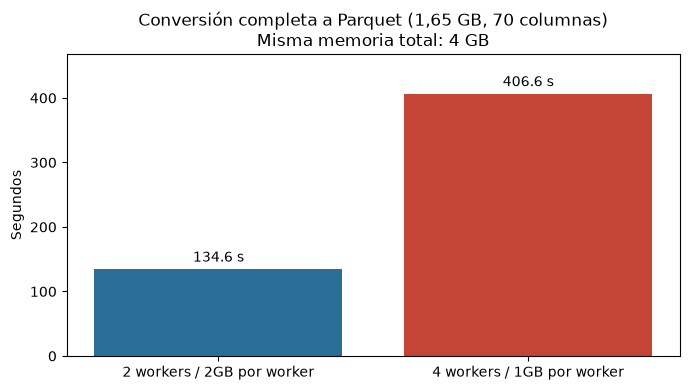

In [4]:
import os
import pandas as pd
import matplotlib.pyplot as plt

RUTA_PQ2 = "datos_anonimizados/reserva_parquet_completo_config2"

def tam_gb(ruta):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(ruta) for f in fs) / 1024**3

# Validación: las dos salidas deben tener las mismas filas y columnas
for ruta in [RUTA_PQ, RUTA_PQ2]:
    pq = dd.read_parquet(ruta)
    print(f"{ruta}: {len(pq):,} filas | {len(pq.columns)} columnas | "
          f"{pq.npartitions} archivos | {tam_gb(ruta):.2f} GB")

# Tabla comparativa
comparacion = pd.DataFrame({"configuracion": list(resultados.keys()),
                            "segundos": list(resultados.values())})
comparacion["veces_vs_config1"] = (comparacion["segundos"] / comparacion["segundos"].iloc[0]).round(2)
display(comparacion)

# Gráfica
fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(comparacion["configuracion"], comparacion["segundos"], color=["#2a6f97", "#c44536"])
ax.bar_label(barras, fmt="%.1f s", padding=3)
ax.set_title("Conversión completa a Parquet (1,65 GB, 70 columnas)\nMisma memoria total: 4 GB")
ax.set_ylabel("Segundos")
ax.set_ylim(0, comparacion["segundos"].max() * 1.15)
plt.tight_layout()
plt.show()

In [5]:
import dask

# Clúster con la configuración más eficiente (la 1)
cluster = LocalCluster(n_workers=2, threads_per_worker=1, memory_limit="2GB")
cliente = Client(cluster)
print("Tablero de Dask:", cliente.dashboard_link)

ddf = dd.read_parquet(RUTA_PQ)

# Tamaño de la base cargada en memoria
mem_gb = ddf.memory_usage(deep=True).sum().compute() / 1024**3
print(f"Tamaño de la base en memoria: {mem_gb:.2f} GB")

# Vacíos y valores distintos de cada columna, sobre la base completa
nulos = ddf.isna().sum().compute()
distintos = pd.Series(dask.compute({c: ddf[c].nunique() for c in ddf.columns})[0])

perfil_completo = pd.DataFrame({
    "tipo": ddf.dtypes.astype(str),
    "vacios": nulos,
    "pct_vacios": (nulos / len(ddf) * 100).round(2),
    "valores_distintos": distintos,
})
perfil_completo["constante"] = perfil_completo["valores_distintos"] <= 1
print("Columnas constantes o vacías en toda la base:", perfil_completo["constante"].sum(), "de", len(perfil_completo))
perfil_completo

Tablero de Dask: http://127.0.0.1:8787/status
Tamaño de la base en memoria: 1.90 GB


2026-10-19 21:57:36,324 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle e413f88bbfcfb07eed17731102d0c1a1 initialized by task ('shuffle-transfer-e413f88bbfcfb07eed17731102d0c1a1', 24) executed on worker tcp://127.0.0.1:53843
2026-10-19 21:57:36,432 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 380eac69c75eb55efa938fed0aff0c9b initialized by task ('shuffle-transfer-380eac69c75eb55efa938fed0aff0c9b', 21) executed on worker tcp://127.0.0.1:53844
2026-10-19 21:57:36,517 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 8b7b12dc7839ec61fc781ab45ea64b6f initialized by task ('shuffle-transfer-8b7b12dc7839ec61fc781ab45ea64b6f', 18) executed on worker tcp://127.0.0.1:53844
2026-10-19 21:57:36,585 - distributed.shuffle._scheduler_plugin - WARNING - Shuffle 9da96703581f5e5a7af904c4912e195e initialized by task ('shuffle-transfer-9da96703581f5e5a7af904c4912e195e', 21) executed on worker tcp://127.0.0.1:53844
2026-10-19 21:57:36,697 - distributed.shuffle._scheduler

Columnas constantes o vacías en toda la base: 39 de 70


,tipo,vacios,pct_vacios,valores_distintos,constante
moneda,string,0,0.0,1,True
sucursal,string,0,0.0,27,False
ramo_tecnico,string,0,0.0,1,True
subramo,string,0,0.0,1,True
ramo_comercial,string,0,0.0,1,True
...,...,...,...,...,...
gastos_de_expedicion_ced_int,float64,0,0.0,1,True
gastos_de_expedicion_ced_ext,float64,0,0.0,1,True
rpnd_retenida,float64,0,0.0,32489,False
rpnd_cedida_interior,float64,0,0.0,1,True


In [6]:
import logging
logging.getLogger("distributed.shuffle").setLevel(logging.ERROR)
pd.set_option("display.max_rows", 100)

# 1) ¿Alguna columna quedó con vacíos? (solo deberían ser las de facultativo)
print("Columnas con vacíos:")
display(perfil_completo[perfil_completo["vacios"] > 0])

# 2) Columnas que sí aportan información
utiles = perfil_completo[~perfil_completo["constante"]]
print(f"Columnas útiles: {len(utiles)}")
display(utiles)

# 3) Columnas constantes y el valor único que tienen en toda la base
constantes = perfil_completo[perfil_completo["constante"]].copy()
constantes["valor_unico"] = ddf[list(constantes.index)].head(1).T.iloc[:, 0]
print(f"Columnas constantes o vacías: {len(constantes)}")
display(constantes[["tipo", "pct_vacios", "valor_unico"]])

Columnas con vacíos:


,tipo,vacios,pct_vacios,valores_distintos,constante
facultativo_no_proporcional_moneda_emision,float64,3316704,100.0,0,True
facultativo_no_proporcional_moneda_equivalente,float64,3316704,100.0,0,True


Columnas útiles: 31


,tipo,vacios,pct_vacios,valores_distintos,constante
sucursal,string,0,0.0,27,False
id_poliza,string,0,0.0,3315424,False
endoso,string,0,0.0,3,False
tipo_de_movimiento,string,0,0.0,2,False
tipo_de_endoso,string,0,0.0,3,False
fecha_de_emision,datetime64[ns],0,0.0,579,False
fecha_inicio_de_vigencia,datetime64[ns],0,0.0,802,False
fecha_fin_de_vigencia,datetime64[ns],0,0.0,1032,False
dias_de_vigencia,float64,0,0.0,186,False
dias_devengados,float64,0,0.0,706,False


Columnas constantes o vacías: 39


,tipo,pct_vacios,valor_unico
moneda,string,0.0,Pesos
ramo_tecnico,string,0.0,8
subramo,string,0.0,1
ramo_comercial,string,0.0,8
tipo_de_operacion,string,0.0,DIRECTA
tasa_de_cambio_de_emision,float64,0.0,1.0
primas_aceptadas_al_interior_moneda_emision,float64,0.0,0.0
primas_aceptadas_al_exterior_moneda_emision,float64,0.0,0.0
primas_cedidas_a_reaseguradores_del_interior_moneda_emision,float64,0.0,0.0
primas_cedidas_a_reaseguradores_del_exterior_moneda_emision,float64,0.0,0.0


In [7]:
# 1) ¿Las columnas "pareja" son idénticas en toda la base?
pares = [
    ("primas_emitidas_moneda_emision", "primas_emitidas_moneda_equivalente"),
    ("primas_canceladas_moneda_emision", "primas_canceladas_moneda_equivalente"),
    ("primas_retenidas_moneda_emision", "primas_retenidas_moneda_equivalente"),
    ("base_calculo_moneda_emision", "base_calculo_moneda_equivalente"),
    ("calculo_reserva_moneda_emision", "calculo_reserva_moneda_equivalente"),
    ("comision", "comision_ret"),
    ("rga", "rga_ret"),
    ("imp_comp_soat", "imp_comp_soat_ret"),
    ("gastos_de_expedicion", "gastos_de_expedicion_ret"),
]
dif_max = dask.compute({f"{a} vs {b}": (ddf[a] - ddf[b]).abs().max() for a, b in pares})[0]
display(pd.Series(dif_max, name="diferencia_maxima").to_frame())

# 2) Comprobar cómo se calcula la RPND retenida
rpnd_recalculada = ((ddf["primas_retenidas_moneda_emision"] + ddf["imp_comp_soat_ret"])
                    * 0.858 * ddf["coeficiente"])
dif = (ddf["rpnd_retenida"] - rpnd_recalculada).abs()

dif_max_rpnd, pct_cuadra, total_rpnd, total_recalc, total_calc_reserva = dask.compute(
    dif.max(), (dif < 1).mean() * 100,
    ddf["rpnd_retenida"].sum(), rpnd_recalculada.sum(), ddf["calculo_reserva_moneda_emision"].sum())

print(f"Filas donde la RPND recalculada cuadra (diferencia < $1): {pct_cuadra:.2f} %")
print(f"Diferencia máxima en una fila: {dif_max_rpnd:,.2f}")
print(f"RPND retenida total:            {total_rpnd:,.0f}")
print(f"RPND recalculada total:         {total_recalc:,.0f}")
print(f"Cálculo reserva (sin imp_comp): {total_calc_reserva:,.0f}")

,diferencia_maxima
primas_emitidas_moneda_emision vs primas_emitidas_moneda_equivalente,0.0
primas_canceladas_moneda_emision vs primas_canceladas_moneda_equivalente,0.0
primas_retenidas_moneda_emision vs primas_retenidas_moneda_equivalente,0.0
base_calculo_moneda_emision vs base_calculo_moneda_equivalente,0.0
calculo_reserva_moneda_emision vs calculo_reserva_moneda_equivalente,0.0
comision vs comision_ret,0.0
rga vs rga_ret,0.0
imp_comp_soat vs imp_comp_soat_ret,0.0
gastos_de_expedicion vs gastos_de_expedicion_ret,0.0


Filas donde la RPND recalculada cuadra (diferencia < $1): 99.93 %
Diferencia máxima en una fila: 35,007.00
RPND retenida total:            610,227,040,624
RPND recalculada total:         610,233,682,006
Cálculo reserva (sin imp_comp): 517,512,835,231


In [10]:
import os

cols = ["sucursal", "id_poliza", "endoso", "tipo_de_movimiento", "tipo_de_endoso",
        "fecha_de_emision", "fecha_inicio_de_vigencia", "fecha_fin_de_vigencia",
        "dias_de_vigencia", "dias_por_devengar", "coeficiente",
        "primas_emitidas_moneda_emision", "primas_canceladas_moneda_emision",
        "primas_retenidas_moneda_emision", "imp_comp_soat",
        "rpnd_retenida", "rpnd_recalculada", "diferencia"]

ddf_rev = ddf.assign(rpnd_recalculada=rpnd_recalculada,
                     diferencia=ddf["rpnd_retenida"] - rpnd_recalculada)
no_cuadran = ddf_rev[ddf_rev["diferencia"].abs() >= 1][cols].compute()

print(f"Filas que no cuadran: {len(no_cuadran):,} | pólizas distintas: {no_cuadran['id_poliza'].nunique():,}")
print(f"Suma de las diferencias: {no_cuadran['diferencia'].sum():,.0f}")
display(no_cuadran.groupby(["tipo_de_movimiento", "tipo_de_endoso"])
        .agg(filas=("id_poliza", "count"), diferencia=("diferencia", "sum")))

os.makedirs("salidas", exist_ok=True)
no_cuadran.to_csv("salidas/polizas_rpnd_no_cuadra.csv", index=False,
                  sep=";", decimal=",", encoding="utf-8-sig")
print("Archivo guardado: salidas/polizas_rpnd_no_cuadra.csv")

Filas que no cuadran: 2,213 | pólizas distintas: 2,212
Suma de las diferencias: -6,641,383


,,filas,diferencia
tipo_de_movimiento,tipo_de_endoso,,
CANCELACION DE POLIZA,DESDE UNA FECHA,1,1.838189e+04
EXPEDICION,EXPEDICION,2212,-6.659765e+06


Archivo guardado: salidas/polizas_rpnd_no_cuadra.csv


In [11]:
cliente.close(); cluster.close()